In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import pandas as pd
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_mdl = os.path.join(pth_data, 'development', 'modeling')
pth_mod = os.path.join(pth_data, 'features', 'biomart', 'modules')
pth_out = os.path.join(pth, 'figures', 'development', 'spectrum')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_mdl, 'trajectories.h5ad'))
adata.obs['t_orig'] = adata.obs.t.astype(float); del adata.obs['t']
adata

AnnData object with n_obs × n_vars = 14458 × 14985
    obs: 'sample', 'celltype', 'source', 't_orig'
    obsm: 'X_pca', 'X_umap', 'X_umap_traj'

In [4]:
mod_fn = sorted(glob.glob(os.path.join(pth_mod, '*.csv')))
get_name = lambda fn: os.path.split(fn)[1].replace('.csv', '')
mod_dict = {get_name(fn) : pd.read_csv(fn) for fn in mod_fn}

# module signatures
g_ref = mod_dict['ref'].mmusculus
for mod, df_mod in mod_dict.items():
    if mod != 'ref':
        print(mod)
        g = df_mod.mmusculus.copy()
        g = g.loc[g.isin(adata.var_names)]
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = mod,
                              ctrl_as_ref = False,
                              gene_pool = g_ref,
                              random_state = 1234)
            adata.obs.loc[msk, mod] = adata_group.obs[mod]

adata.obsm['X_spectrum'] = adata.obs[['late', 'early']].values

early
late


In [5]:
t_lim = {
    'GSE162534'         : [10, 1e5],
    'GSE229103'         : [6, 1e5],
    'rRNAModifications' : [0, 20]}

In [6]:
# select spectrum (t_min < t < t_max)
for src in adata.obs.source.cat.categories:
    msk = (adata.obs.source == src)
    t_min, t_max = t_lim[src]
    t = adata[msk].obs.t_orig
    spectrum = ((t > t_min) & (t < t_max)).astype(str)
    adata.obs.loc[msk, 'spectrum'] = spectrum
    print(src, (spectrum == 'True').sum())

GSE162534 2811
GSE229103 2190
rRNAModifications 1404


In [7]:
adata = adata[adata.obs.spectrum == 'True'].copy()
adata

AnnData object with n_obs × n_vars = 6405 × 14985
    obs: 'sample', 'celltype', 'source', 't_orig', 'early', 'late', 'spectrum'
    obsm: 'X_pca', 'X_umap', 'X_umap_traj', 'X_spectrum'

inferring a principal curve --> parameters used 
    20 principal points, mu = 10, lambda = 0.0001
    finished (0:00:02) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.


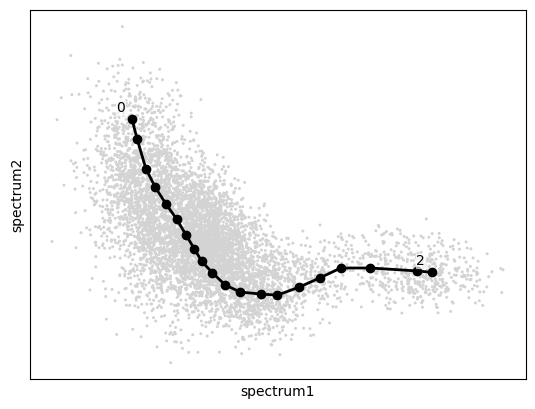

In [8]:
scf.tl.curve(adata, Nodes = 20, epg_lambda = 1e-4, epg_mu = 10,
             use_rep = 'X_spectrum', plot = True, basis = 'spectrum')

In [9]:
scf.tl.root(adata, 0)

node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [10]:
scf.tl.pseudotime(adata)

projecting cells onto the principal graph
    finished (0:00:01) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


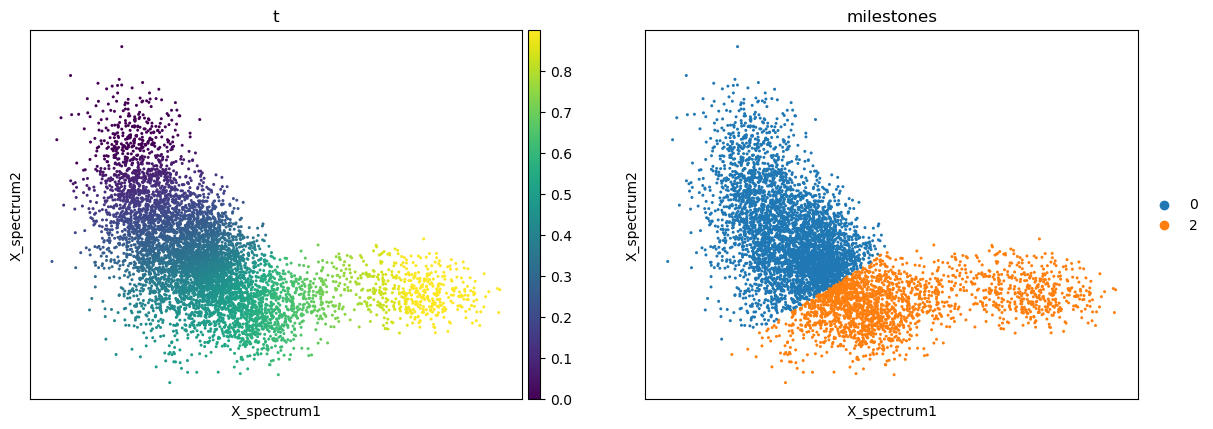

In [11]:
sc.pl.embedding(adata, 'X_spectrum', color = ['t', 'milestones'])

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


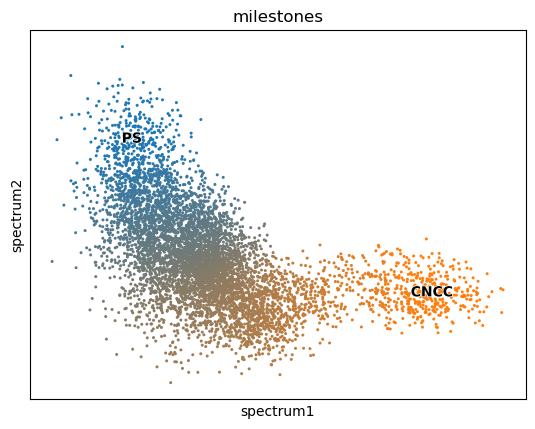

In [12]:
scf.tl.rename_milestones(adata, new = {'0' : 'PS', '2' : 'CNCC'})
scf.pl.milestones(adata, basis = 'spectrum', annotate = True)

In [13]:
del adata.uns['epg']
adata.write(os.path.join(pth_mdl, 'spectrum.h5ad'))
adata

AnnData object with n_obs × n_vars = 6405 × 14985
    obs: 'sample', 'celltype', 'source', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones'
    uns: 'graph', 'pseudotime_list', 'milestones_colors', 'seg_colors'
    obsm: 'X_pca', 'X_umap', 'X_umap_traj', 'X_spectrum', 'X_R'

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


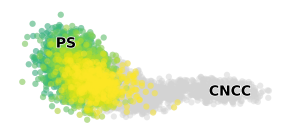

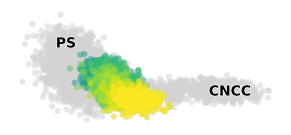

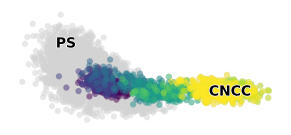

In [14]:
# plot trajectories
for src, sdf in adata.obs.groupby('source', observed = True):
    adata_src = adata[sdf.index].copy()
    fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
    sc.pl.embedding(adata, 'X_spectrum', size = 80, alpha = .5,
                    frameon = False, show = False, ax = ax)
    sc.pl.embedding(adata_src, 'X_spectrum', size = 80, alpha = .5,
                    color = 't_orig', vmin = 0, colorbar_loc = None,
                    frameon = False, show = False, ax = ax)
    scf.pl.milestones(adata, basis = 'spectrum', annotate = True,
                      alpha = 0, show = False, ax = ax)
    ax.set_title('')
    fn = os.path.join(pth_out, f'{src}.pdf')
    plt.savefig(fn, bbox_inches = 'tight')

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


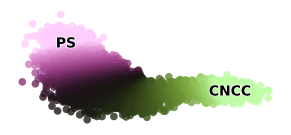

In [15]:
# plot spectrum (combined)
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_spectrum', size = 120, alpha = .8,
                color = 't', cmap = 'vanimo', colorbar_loc = None,
                frameon = False, show = False, ax = ax)
scf.pl.milestones(adata, basis = 'spectrum', annotate = True,
                  alpha = 0, show = False, ax = ax)
ax.set_title('')
fn = os.path.join(pth_out, 'combined.pdf')
plt.savefig(fn, bbox_inches = 'tight')